In [29]:
import os
os.environ['KERAS_BACKEND'] = 'jax'
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import keras
import pickle
import inspect

import bayesflow as bf

In [30]:
FLOOR = 1e-3  


def b_fixed(t, a):
    """Constant boundary (baseline model)."""
    return np.full_like(t, a)


def b_linear(t, a, k):
    """Linear collapse, rate k per second."""
    return np.maximum(a - k * t, FLOOR)


def b_exponential(t, a, lam):
    """Exponential decay to zero.  b(0) = a,  b(inf) = 0."""
    return np.maximum(a * np.exp(-t / lam), FLOOR)


def b_sigmoid(t, a, k_sig, t_mid, a_min):
    """
    Logistic collapse, normalised so that b(0) = a exactly.
        g(t) = 1 / (1 + exp(-k_sig * (t - t_mid)))
        b(t) = a * [a_min + (1 - a_min) * (1 - g(t)) / (1 - g(0))]
    k_sig : steepness    t_mid : inflection point in s    a_min : asymptote fraction

    Since k_sig, t_mid > 0 we have g(0) <= 0.5, so the denominator is bounded
    below by 0.5 and this cannot blow up.
    """
    g0 = 1.0 / (1.0 + np.exp(k_sig * t_mid))
    g = 1.0 / (1.0 + np.exp(-k_sig * (t - t_mid)))
    return np.maximum(a * (a_min + (1.0 - a_min) * (1.0 - g) / (1.0 - g0)), FLOOR)


In [31]:
BOUNDARY_FNS = {
    "fixed":       b_fixed,
    "linear":      b_linear,
    "exponential": b_exponential,
    "sigmoid":     b_sigmoid,
  
}
MODEL_NAMES = list(BOUNDARY_FNS)

CORE_PRIORS = {
    "v_scale": (0.5, 9.0),     
    "a":       (0.4, 2.0),     
    "t0":      (0.15, 0.45),   
    "sv":      (0.0, 1.5),     
}

SHAPE_PRIORS = {
    "fixed":       {},
    "linear":      {"k": (0.0, 3.0)},
    "exponential": {"lam": (0.05, 3.0)},
    "sigmoid":     {"k_sig": (2.0, 15.0), "t_mid": (0.10, 1.20), "a_min": (0.0, 0.9)},
}


def param_names(model):
    """Ordered list of inferred parameters for a boundary model."""
    return list(CORE_PRIORS) + list(SHAPE_PRIORS[model])


def sample_params(model, rng=None):
    rng = np.random.default_rng() if rng is None else rng
    ranges = {**CORE_PRIORS, **SHAPE_PRIORS[model]}
    return {k: float(rng.uniform(lo, hi)) for k, (lo, hi) in ranges.items()}


def boundary_trace(model, params, dt=None, max_time=None):
    dt = DT if dt is None else dt
    max_time = MAX_TIME if max_time is None else max_time
    t = np.arange(0.0, max_time, dt)
    shape = {k: params[k] for k in SHAPE_PRIORS[model]}
    return t, BOUNDARY_FNS[model](t, a=params["a"], **shape)

In [32]:
DT = 0.005                 # Euler-Maruyama step (s)
DEADLINE = 1.35            # enforced response deadline -- OVERWRITTEN FROM DATA in cell 29
MAX_TIME = DEADLINE        # nothing past the deadline is observable
S_NOISE = 1.0              # diffusion coefficient (s = 1 convention)

DIFFICULTY_LEVELS = np.array([0.10, 0.20, 0.30, 0.40, 0.50, 0.60])

N_TRIALS_PER_COH = 60      #  360 trials per dataset (= per participant)

#  Simplified design: only one cue type and one deadline condition, to reduce the number of parameters to infer.
# done as per review in the presentation.
CUE = 0                    # 0 = speed, 1 = accuracy
HAS_DEADLINE = 1

In [33]:
FLASH_PAIRS = [
    (0.55, 0.45),
    (0.60, 0.40),
    (0.65, 0.35),  
    (0.70, 0.30),
    (0.75, 0.25),
    (0.80, 0.20),
]

DIFFICULTY_LEVELS = np.array([round(abs(p1 - p2), 2) for p1, p2 in FLASH_PAIRS])
COH_TO_PAIR = {c: p for c, p in zip(DIFFICULTY_LEVELS, FLASH_PAIRS)}

In [34]:
def ddm_data_simulator(model, params, difficulty_levels=None, n_per_coh=None,
                     dt=None, deadline=None, s_noise=None, rng=None):
    """
    Simulate one participant in one condition cell.

    The boundary is SHARED across difficulties; only the drift rate changes.
    That shared-boundary constraint across difficulty levels is what makes the
    collapse rate identifiable -- with a single difficulty, fixed and collapsing
    boundaries mimic each other.

    Accuracy coding: drift is positive toward the correct response, so the upper
    boundary is 'correct'. This matches using `acc` as the choice variable.

    Returns
    -------
    rt        : (n,) response time in s, np.nan if no response
    choice    : (n,) 1 = correct, 0 = error, -1 = no response before deadline
    coherence : (n,) difficulty of each trial
    """
    rng = np.random.default_rng() if rng is None else rng
    difficulty_levels = DIFFICULTY_LEVELS if difficulty_levels is None else np.asarray(difficulty_levels, float)
    n_per_coh = N_TRIALS_PER_COH if n_per_coh is None else n_per_coh
    dt = DT if dt is None else dt
    deadline = DEADLINE if deadline is None else deadline
    s_noise = S_NOISE if s_noise is None else s_noise

    coh = np.repeat(difficulty_levels, n_per_coh)
    n = coh.size

    t_dec_max = max(deadline - params["t0"], dt)
    t_grid = np.arange(0.0, t_dec_max, dt)

    shape = {k: params[k] for k in SHAPE_PRIORS[model]}
    bnd = BOUNDARY_FNS[model](t_grid, a=params["a"], **shape)

    v = params["v_scale"] * coh
    if params.get("sv", 0.0) > 0:
        v = rng.normal(v, params["sv"])

    x = np.zeros(n)                     
    rt = np.full(n, np.nan)
    choice = np.full(n, -1, dtype=np.int8)
    active = np.ones(n, dtype=bool)
    sqrt_dt = np.sqrt(dt)

    for step, b in enumerate(bnd):

        if not active.any():
            break

        t_now = params["t0"] + step * dt

        for i in range(n):                     

            if not active[i]:                   
                continue

            if x[i] >= b:                      
                rt[i] = t_now
                choice[i] = 1
                active[i] = False               
                continue                        

            if x[i] <= -b:                      
                rt[i] = t_now
                choice[i] = 0
                active[i] = False
                continue

            drift_part = v[i] * dt
            noise_part = s_noise * sqrt_dt * rng.standard_normal()
            x[i] += drift_part + noise_part

    return rt, choice, coh


def pack_observations(rt, choice, coherence):
    """
    Shape trials into the (n_trials, 4) array the summary network consumes.
    Columns: [rt (0 if no response), correct, coherence, responded]

    Non-responses get an explicit indicator column instead of the sentinel
    rt = -1.0 used in your cell 10. A sentinel inside a continuous variable
    forces the network to learn that -1 means 'missing' rather than 'very fast',
    and the deadline-miss rate is one of the most informative statistics you have
    about the collapse rate -- it deserves its own channel.
    """
    choice = np.asarray(choice)
    responded = (choice >= 0).astype(np.float32)
    rt_safe = np.where(choice >= 0, rt, 0.0).astype(np.float32)
    correct = np.where(choice == 1, 1.0, 0.0).astype(np.float32)
    return np.stack([rt_safe, correct,
                     np.asarray(coherence, np.float32), responded], axis=-1)

In [35]:
def simulate_full_dataset(model, n_participants=24, seed=0):
    """Simulated data for the fixed condition cell, in empirical column format."""
    rng = np.random.default_rng(seed)
    rows, truth = [], []

    for pp in range(1, n_participants + 1):
        params = sample_params(model, rng)
        rt, choice, coh = ddm_data_simulator(model, params, rng=rng)

        for r, c, k in zip(rt, choice, coh):
            p1, p2 = COH_TO_PAIR[round(float(k), 2)]
            rows.append({
                "pp": pp,
                "cue": CUE,
                "has_deadline": HAS_DEADLINE,
                "difficulty_pair": f"[{p1}, {p2}]",   #
                "p1": p1,
                "p2": p2,
                "difficulty": k,                
                "rt": np.nan if c == -1 else r,
                "acc": np.nan if c == -1 else int(c == 1),
            })

        truth.append({"pp": pp, "model": model, **params})

    return pd.DataFrame(rows), pd.DataFrame(truth)

In [36]:
def make_prior(model):
    def prior():
        return sample_params(model, np.random.default_rng())
    return prior

In [37]:
def make_likelihood(model):
    names = param_names(model)

    def likelihood(**params):
        rt, choice, coh = ddm_data_simulator(model, params, rng=np.random.default_rng())
        return {"obs": pack_observations(rt, choice, coh)}

    # BayesFlow matches prior keys to likelihood arguments by name, so the
    # signature has to be explicit rather than **params
    likelihood.__signature__ = inspect.Signature(
        [inspect.Parameter(nm, inspect.Parameter.POSITIONAL_OR_KEYWORD) for nm in names]
    )
    return likelihood

In [53]:
for mdl in MODEL_NAMES:
    print(f"{mdl:12s} {inspect.signature(make_likelihood(mdl))}")

fixed        (v_scale, a, t0, sv)
linear       (v_scale, a, t0, sv, k)
exponential  (v_scale, a, t0, sv, lam)
sigmoid      (v_scale, a, t0, sv, k_sig, t_mid, a_min)


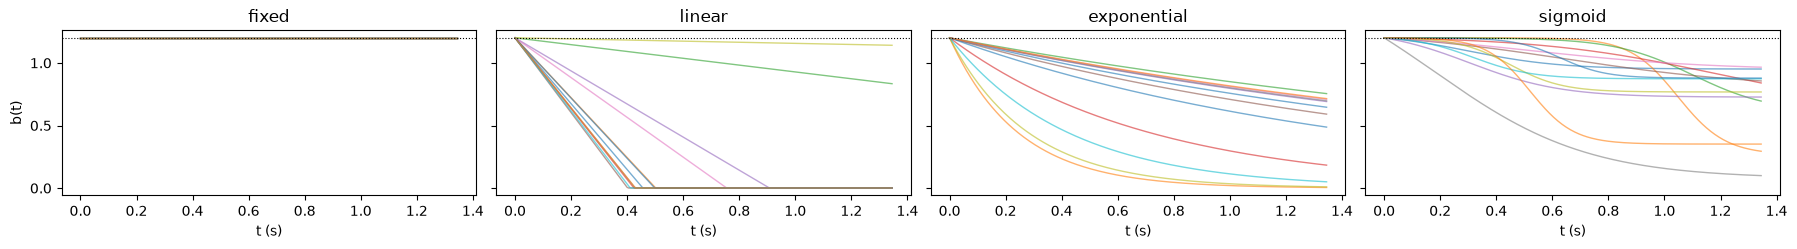

In [38]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, len(MODEL_NAMES), figsize=(18, 2.6), sharey=True)
for ax, mdl in zip(axes, MODEL_NAMES):
    for _ in range(12):
        p = sample_params(mdl, rng); p["a"] = 1.2
        t, b = boundary_trace(mdl, p)
        ax.plot(t, b, lw=1, alpha=0.6)
    ax.axhline(1.2, ls=":", c="k", lw=0.8)   # every model must start here
    ax.set_title(mdl); ax.set_xlabel("t (s)")
axes[0].set_ylabel("b(t)"); plt.tight_layout(); plt.show()

In [39]:
for mdl in MODEL_NAMES:
    miss, acc, med = [], [], []
    for _ in range(200):
        rt, ch, _ = ddm_data_simulator(mdl, sample_params(mdl, rng), rng=rng)
        ok = ch >= 0
        miss.append(1 - ok.mean())
        acc.append(np.mean(ch[ok] == 1) if ok.any() else np.nan)
        med.append(np.nanmedian(rt))
    q = lambda v: np.nanquantile(v, [.1, .5, .9]).round(2)
    print(f"{mdl:12s} miss {q(miss)}   acc {q(acc)}   median RT {q(med)}")

fixed        miss [0.01 0.22 0.6 ]   acc [0.65 0.88 0.98]   median RT [0.47 0.76 0.99]
linear       miss [0.  0.  0.2]   acc [0.64 0.83 0.94]   median RT [0.4  0.64 0.87]
exponential  miss [0.   0.01 0.2 ]   acc [0.62 0.83 0.95]   median RT [0.41 0.63 0.86]
sigmoid      miss [0.   0.03 0.35]   acc [0.71 0.86 0.96]   median RT [0.44 0.69 0.96]


In [40]:
def make_adapter(model):
    return (
        bf.adapters.Adapter()
        .to_array()
        .convert_dtype("float64", "float32")
        .rename("obs", "summary_variables")
        .concatenate(param_names(model), into="inference_variables")
        .keep(["summary_variables", "inference_variables"])
    )


def make_workflow(model, checkpoint_dir=None, summary_dim=32):
    simulator = bf.make_simulator([make_prior(model), make_likelihood(model)])
    kwargs = {}
    if checkpoint_dir is not None:
        os.makedirs(checkpoint_dir, exist_ok=True)
        kwargs = dict(checkpoint_filepath=checkpoint_dir, checkpoint_name=f"ddm_{model}")
    return bf.BasicWorkflow(
        simulator=simulator,
        adapter=make_adapter(model),
        inference_network=bf.networks.CouplingFlow(
            num_coupling_layers=6, subnet_kwargs={"widths": (128, 128)}
        ),
        summary_network=bf.networks.DeepSet(summary_dim=summary_dim),
        inference_variables=param_names(model),
        **kwargs,
    )

In [41]:
wf = make_workflow("exponential")
d = wf.simulate(4)
print({k: np.asarray(v).shape for k, v in d.items()})

{'v_scale': (4, 1), 'a': (4, 1), 't0': (4, 1), 'sv': (4, 1), 'lam': (4, 1), 'obs': (4, 360, 4)}


In [42]:
# EPOCHS, BATCH_SIZE, N_BATCHES = 30, 64, 200
EPOCHS, BATCH_SIZE, N_BATCHES = 20, 64, 200
PROJECT_MODEL_NAMES = ["exponential"]

workflows, histories = {}, {}
for mdl in PROJECT_MODEL_NAMES:
    print(f"=== {mdl}  {param_names(mdl)} ===")
    wf = make_workflow(mdl, checkpoint_dir=f"checkpoints/{mdl}")
    histories[mdl] = wf.fit_online(epochs=EPOCHS, batch_size=BATCH_SIZE,
                                   num_batches_per_epoch=N_BATCHES)
    workflows[mdl] = wf

with open("networks/histories.pkl", "wb") as f:
    pickle.dump({k: v.history for k, v in histories.items()}, f)

Existing checkpoints are not automatically loaded. Upon refitting, the checkpoints will be overwritten.
To load the stored approximator from the checkpoint, use approximator = keras.saving.load_model("checkpoints/exponential/ddm_exponential.keras")
INFO:bayesflow:Fitting on dataset instance of OnlineDataset.
INFO:bayesflow:Building on a test batch.


=== exponential  ['v_scale', 'a', 't0', 'sv', 'lam'] ===
Epoch 1/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 232s 1s/step - loss: 5.3658
Epoch 2/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 228s 1s/step - loss: 3.3632
Epoch 3/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 226s 1s/step - loss: 2.5478
Epoch 4/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 223s 1s/step - loss: 2.0294
Epoch 5/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 223s 1s/step - loss: 1.4893
Epoch 6/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 224s 1s/step - loss: 0.9682
Epoch 7/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 227s 1s/step - loss: 0.7995
Epoch 8/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 223s 1s/step - loss: 0.4431
Epoch 9/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 218s 1s/step - loss: 0.2136
Epoch 10/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 220s 1s/step - loss: 0.0703
Epoch 11/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 216s 1s/step - loss: -0.0596
Epoch 12/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 225s 1s/step - loss: -0.1812
Epoch 13/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 229s 1s/step - loss: -0.2706
Epoch 14/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 228s 1s/ste

INFO:bayesflow:Training completed in 1.25 hours.
INFO:bayesflow:Training is now finished.
You can find the trained approximator at 'checkpoints/exponential/ddm_exponential.keras'.
To load it, use approximator = keras.saving.load_model("checkpoints/exponential/ddm_exponential.keras").


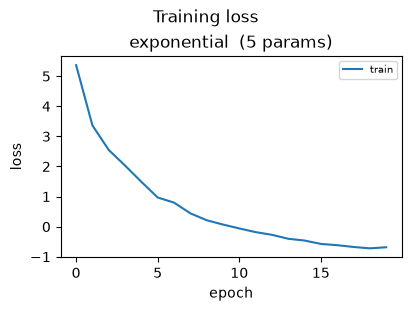

In [43]:
n_mdl = len(PROJECT_MODEL_NAMES)
fig, axes = plt.subplots(1, n_mdl, figsize=(4 * n_mdl, 3),
                         squeeze=False, layout="constrained")
axes = axes[0]

for ax, mdl in zip(axes, PROJECT_MODEL_NAMES):
    h = histories[mdl].history
    ax.plot(h["loss"], label="train")
    if "val_loss" in h:
        ax.plot(h["val_loss"], label="validation")
    ax.set_title(f"{mdl}  ({len(param_names(mdl))} params)")
    ax.set_xlabel("epoch"); ax.legend(fontsize=7)

axes[0].set_ylabel("loss")
fig.suptitle("Training loss")
plt.show()

exponential  final loss = -0.6841


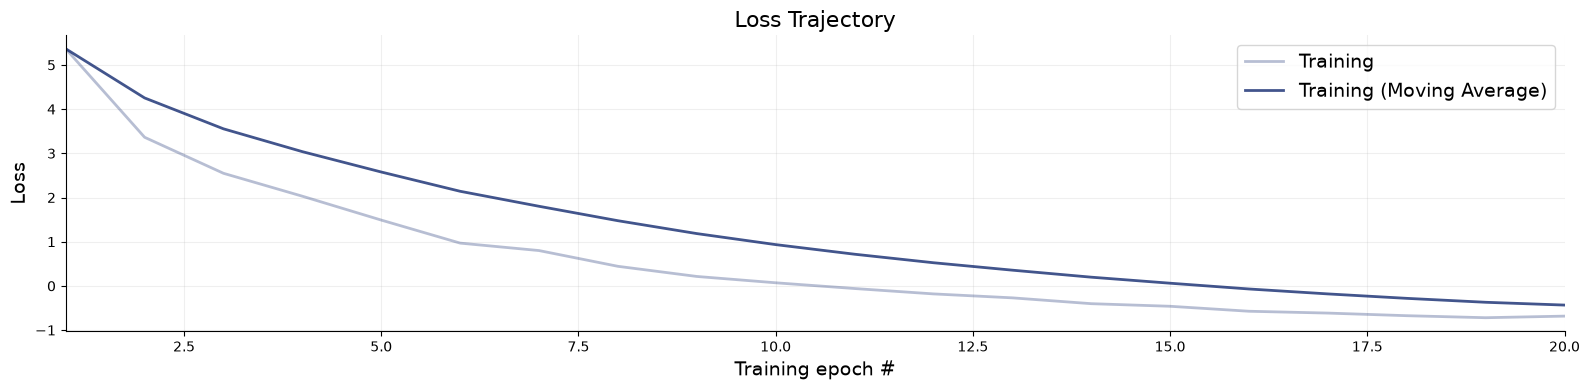

In [44]:
for mdl in PROJECT_MODEL_NAMES:
    bf.diagnostics.loss(histories[mdl])
    print(f"{mdl:12s} final loss = {histories[mdl].history['loss'][-1]:.4f}")

Sampling: 100%|██████████| 1/1 [00:00<00:00,  4.45batch/s]


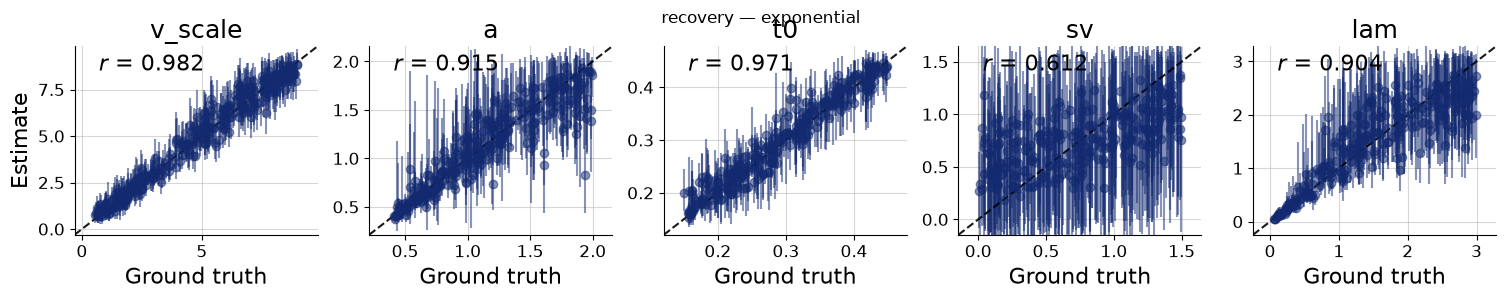

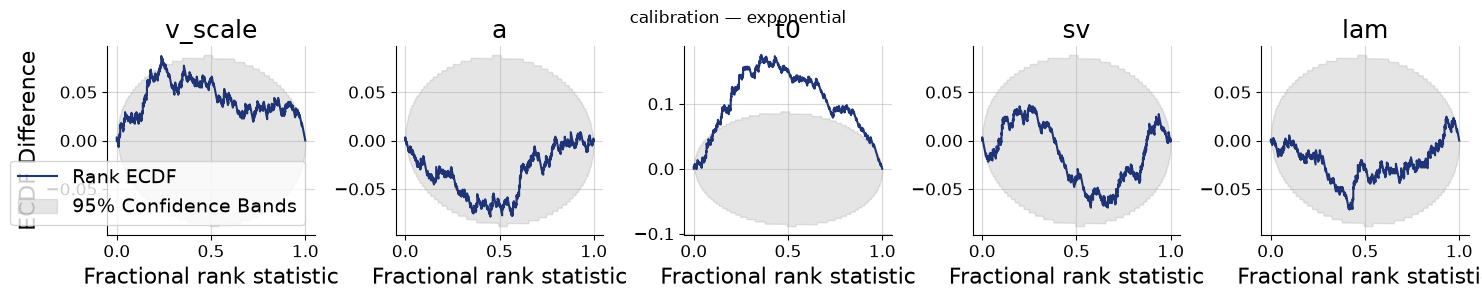

In [45]:
val, post = {}, {}
for mdl in PROJECT_MODEL_NAMES:
    val[mdl] = workflows[mdl].simulate(300)
    post[mdl] = workflows[mdl].approximator.sample(num_samples=500, conditions=val[mdl])
    w = 3 * len(param_names(mdl))
    
    bf.diagnostics.plots.recovery(post[mdl], val[mdl], figsize=(w, 3))
    plt.suptitle(f"recovery — {mdl}"); plt.show()
    bf.diagnostics.plots.calibration_ecdf(post[mdl], val[mdl], figsize=(w, 3))
    plt.suptitle(f"calibration — {mdl}"); plt.show()


In [46]:
emp = pd.read_csv("../data/Katsimposis/experiment-2-Flash.csv")

emp["difficulty"] = (
    emp["difficulty"].astype(str).str.strip()
    .str.replace(r"[\[\]]", "", regex=True)
    .str.split(",")
    .apply(lambda s: round(abs(float(s[0]) - float(s[1])), 2))
)
emp["has_deadline"] = (emp["deadline"].astype(str).str.strip().str.lower() == "deadline").astype(int)
emp["cue"] = (emp["cue"].astype(str).str.strip().str.upper() == "AC").astype(int)

assert emp["difficulty"].notna().all()
print(sorted(emp["difficulty"].unique()))
print(emp.groupby(["cue", "has_deadline"]).size())

[np.float64(0.1), np.float64(0.2), np.float64(0.3), np.float64(0.4)]
cue  has_deadline
0    0               4800
     1               4776
1    0               4800
     1               4657
dtype: int64


In [47]:
cell = emp[(emp.cue == CUE) & (emp.has_deadline == HAS_DEADLINE)]

DEADLINE = float(np.nanpercentile(cell["rt"], 99.9))
MAX_TIME = DEADLINE
DIFFICULTY_LEVELS = np.array(sorted(cell["difficulty"].unique()))
N_TRIALS_PER_COH = int(round(cell.groupby("pp").size().median() / len(DIFFICULTY_LEVELS)))

print(f"deadline={DEADLINE:.3f}s | {len(DIFFICULTY_LEVELS)} difficulty_levels | "
      f"{N_TRIALS_PER_COH} trials/coherence | {cell.pp.nunique()} participants")

deadline=1.302s | 4 difficulty_levels | 50 trials/coherence | 24 participants


In [48]:

QUANTILES = [.1, .3, .5, .7, .9]


def _defective_cdf(rt, correct_mask, n_total):
    """CDFs scaled by response proportion, so correct and error curves
    asymptote at their respective response rates rather than at 1."""
    rt = np.asarray(rt, float)
    ok = ~np.isnan(rt)
    rt_c = np.sort(rt[ok & correct_mask])
    rt_e = np.sort(rt[ok & ~correct_mask])
    y_c = np.arange(1, rt_c.size + 1) / max(rt_c.size, 1) * (rt_c.size / n_total)
    y_e = np.arange(1, rt_e.size + 1) / max(rt_e.size, 1) * (rt_e.size / n_total)
    return (rt_c, y_c), (rt_e, y_e)


def plot_insight_summary(df, title="", coh_col="difficulty", deadline=None):
    """
    Descriptive summary of one condition cell (one cue, deadline only,
    all difficulty levels).

    Expects columns: pp, <coh_col>, rt, acc   with acc = NaN for missed deadlines.
    """
    deadline = DEADLINE if deadline is None else deadline

    d = df.copy()
    d["missed"] = d["acc"].isna()
    d["rt_valid"] = np.where(d["missed"], np.nan, d["rt"])
    cohs = np.sort(d[coh_col].unique())

    fig = plt.figure(figsize=(16, 9), layout="constrained")
    gs = fig.add_gridspec(2, 3)
    C, CM = "#377eb8", "#d95f02"
    rng_j = np.random.default_rng(0)
    jit = lambda n: rng_j.uniform(-0.006, 0.006, size=n)

    ax = fig.add_subplot(gs[0, 0])
    pp_acc = d[~d.missed].groupby(["pp", coh_col])["acc"].mean().reset_index()
    ax.scatter(pp_acc[coh_col] + jit(len(pp_acc)), pp_acc["acc"], s=16, alpha=.35, color=C)
    mu = pp_acc.groupby(coh_col)["acc"].mean()
    ax.plot(mu.index, mu.values, "o-", color=C, lw=2)
    ax.axhline(.5, ls=":", c="k", lw=.8)
    ax.set_ylim(.4, 1.02); ax.set_xlabel("coherence |p1 - p2|"); ax.set_ylabel("accuracy")
    ax.set_title("Psychometric function\n(dots = participants)")

    ax = fig.add_subplot(gs[0, 1])
    pp_rt = d.groupby(["pp", coh_col])["rt_valid"].mean().reset_index()
    ax.scatter(pp_rt[coh_col] + jit(len(pp_rt)), pp_rt["rt_valid"], s=16, alpha=.35, color=C)
    mu = pp_rt.groupby(coh_col)["rt_valid"].mean()
    ax.plot(mu.index, mu.values, "o-", color=C, lw=2)
    ax.axhline(deadline, ls="--", c="firebrick", lw=1, label=f"deadline {deadline:.2f}s")
    ax.set_xlabel("coherence |p1 - p2|"); ax.set_ylabel("mean RT (s)")
    ax.set_title("Chronometric function"); ax.legend(fontsize=7)

    ax = fig.add_subplot(gs[0, 2])
    for q in QUANTILES:
        yq = [np.nanquantile(d.loc[d[coh_col] == c, "rt_valid"], q) for c in cohs]
        ax.plot(cohs, yq, "o-", lw=1.4, label=f"q{int(q*100)}")
    ax.axhline(deadline, ls="--", c="firebrick", lw=1)
    ax.set_xlabel("coherence |p1 - p2|"); ax.set_ylabel("RT (s)")
    ax.set_title("RT quantiles by difficulty\n(fanning-in of slow quantiles = collapse)")
    ax.legend(fontsize=6, ncol=2)

    ax = fig.add_subplot(gs[1, 0])
    for c, ls in zip([cohs[0], cohs[-1]], ["-", "--"]):
        sub = d[d[coh_col] == c]
        (xc, yc), (xe, ye) = _defective_cdf(sub["rt_valid"],
                                            (sub["acc"] == 1).to_numpy(), len(sub))
        ax.plot(xc, yc, ls, color=C, lw=1.6, label=f"correct, coh={c:.2f}")
        ax.plot(xe, ye, ls, color=CM, lw=1.6, label=f"error,   coh={c:.2f}")
    ax.axvline(deadline, ls="--", c="firebrick", lw=1)
    ax.set_xlabel("RT (s)"); ax.set_ylabel("defective CDF")
    ax.set_title("Slow-error signature\n(errors left of correct = collapsing bound)")
    ax.legend(fontsize=6)

    ax = fig.add_subplot(gs[1, 1])
    pp_miss = d.groupby(["pp", coh_col])["missed"].mean().reset_index()
    ax.scatter(pp_miss[coh_col] + jit(len(pp_miss)), pp_miss["missed"], s=16, alpha=.35, color=CM)
    mu = pp_miss.groupby(coh_col)["missed"].mean()
    ax.plot(mu.index, mu.values, "o-", color=CM, lw=2)
    ax.set_xlabel("coherence |p1 - p2|"); ax.set_ylabel("deadline-miss rate")
    ax.set_title(f"Missed deadlines (overall {d['missed'].mean():.3f})")

    ax = fig.add_subplot(gs[1, 2])
    ax.hist(d.loc[d.acc == 1, "rt_valid"].dropna(), bins=50, density=True,
            alpha=.55, color=C, label="correct")
    ax.hist(d.loc[d.acc == 0, "rt_valid"].dropna(), bins=50, density=True,
            histtype="step", lw=1.8, color=CM, label="error")
    ax.axvline(deadline, ls="--", c="firebrick", lw=1)
    ax.set_xlabel("RT (s)"); ax.set_ylabel("density")
    ax.set_title("RT distribution"); ax.legend(fontsize=7)

    fig.suptitle(title or "Single condition cell: all difficulty levels", fontsize=14)
    plt.show()


def plot_design_check(df, coh_col="difficulty"):
    """
    Replaces plot_difficulty_assignment.

    Every participant must contribute trials at EVERY difficulty -- that is the
    shared-boundary-across-difficulty constraint the whole design rests on. A
    row with gaps means the old one-difficulty-per-participant bug is back.
    """
    tab = df.pivot_table(index="pp", columns=coh_col, values="rt", aggfunc="size").fillna(0)
    fig, ax = plt.subplots(figsize=(7, max(3, 0.22 * len(tab))), layout="constrained")
    im = ax.imshow(tab.values, aspect="auto", cmap="viridis")
    ax.set_xticks(range(tab.shape[1]))
    ax.set_xticklabels([f"{c:.2f}" for c in tab.columns])
    ax.set_yticks(range(len(tab))); ax.set_yticklabels(tab.index, fontsize=6)
    ax.set_xlabel("coherence"); ax.set_ylabel("participant")
    ax.set_title("Trials per participant x difficulty")
    fig.colorbar(im, ax=ax, label="n trials"); plt.show()

    if (tab.values == 0).any():
        n = int((tab.values == 0).sum())
        print(f"WARNING: {n} participant x difficulty combination(s) with zero trials.")
    else:
        print(f"OK: all {len(tab)} participants have trials at all "
              f"{tab.shape[1]} difficulties (min {int(tab.values.min())} per cell).")


def plot_model_comparison_overlay(emp_df, sim_dfs, coh_col="difficulty"):
    """Empirical vs simulated RT quantiles, one panel per boundary model."""
    cohs = np.sort(emp_df[coh_col].unique())
    emp = emp_df.assign(rt_valid=np.where(emp_df["acc"].isna(), np.nan, emp_df["rt"]))
    fig, axes = plt.subplots(1, len(sim_dfs), figsize=(3.3 * len(sim_dfs), 3.2), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, (mdl, sdf) in zip(axes, sim_dfs.items()):
        s = sdf.assign(rt_valid=np.where(sdf["acc"].isna(), np.nan, sdf["rt"]))
        for q in QUANTILES:
            ax.plot(cohs, [np.nanquantile(emp.loc[emp[coh_col] == c, "rt_valid"], q) for c in cohs],
                    "o-", color="steelblue", lw=1.2)
            ax.plot(cohs, [np.nanquantile(s.loc[s[coh_col] == c, "rt_valid"], q) for c in cohs],
                    "s--", color="darkorange", lw=1.2)
        ax.set_title(mdl); ax.set_xlabel("coherence")
    axes[0].set_ylabel("RT quantile (s)")
    axes[0].plot([], [], "o-", color="steelblue", label="empirical")
    axes[0].plot([], [], "s--", color="darkorange", label="simulated")
    axes[0].legend(fontsize=7)
    plt.tight_layout(); plt.show()

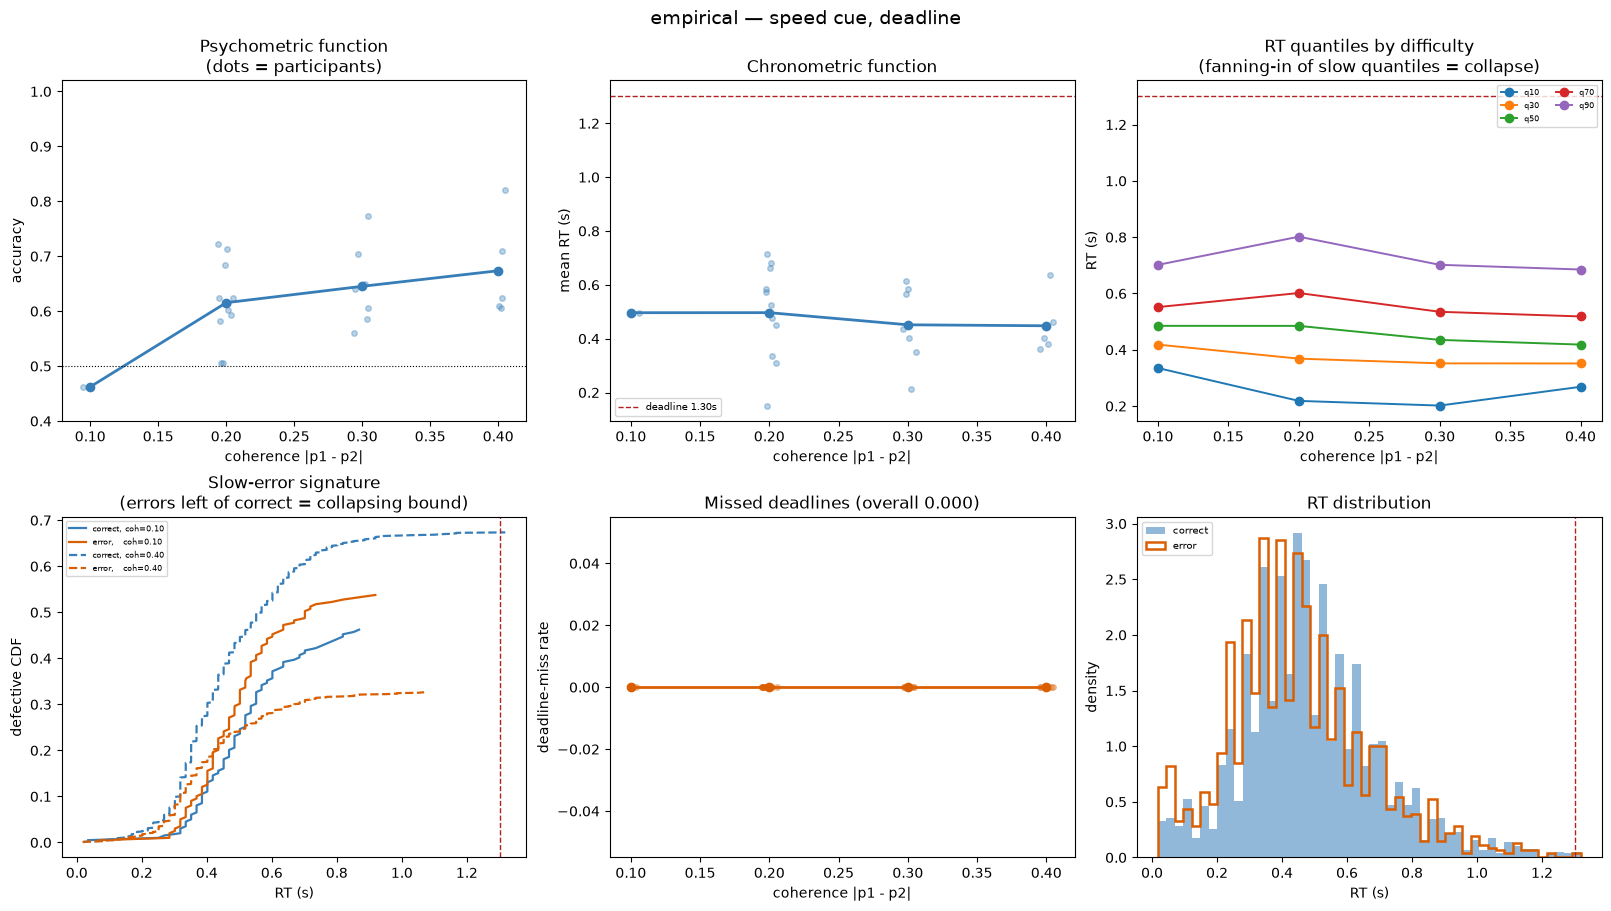

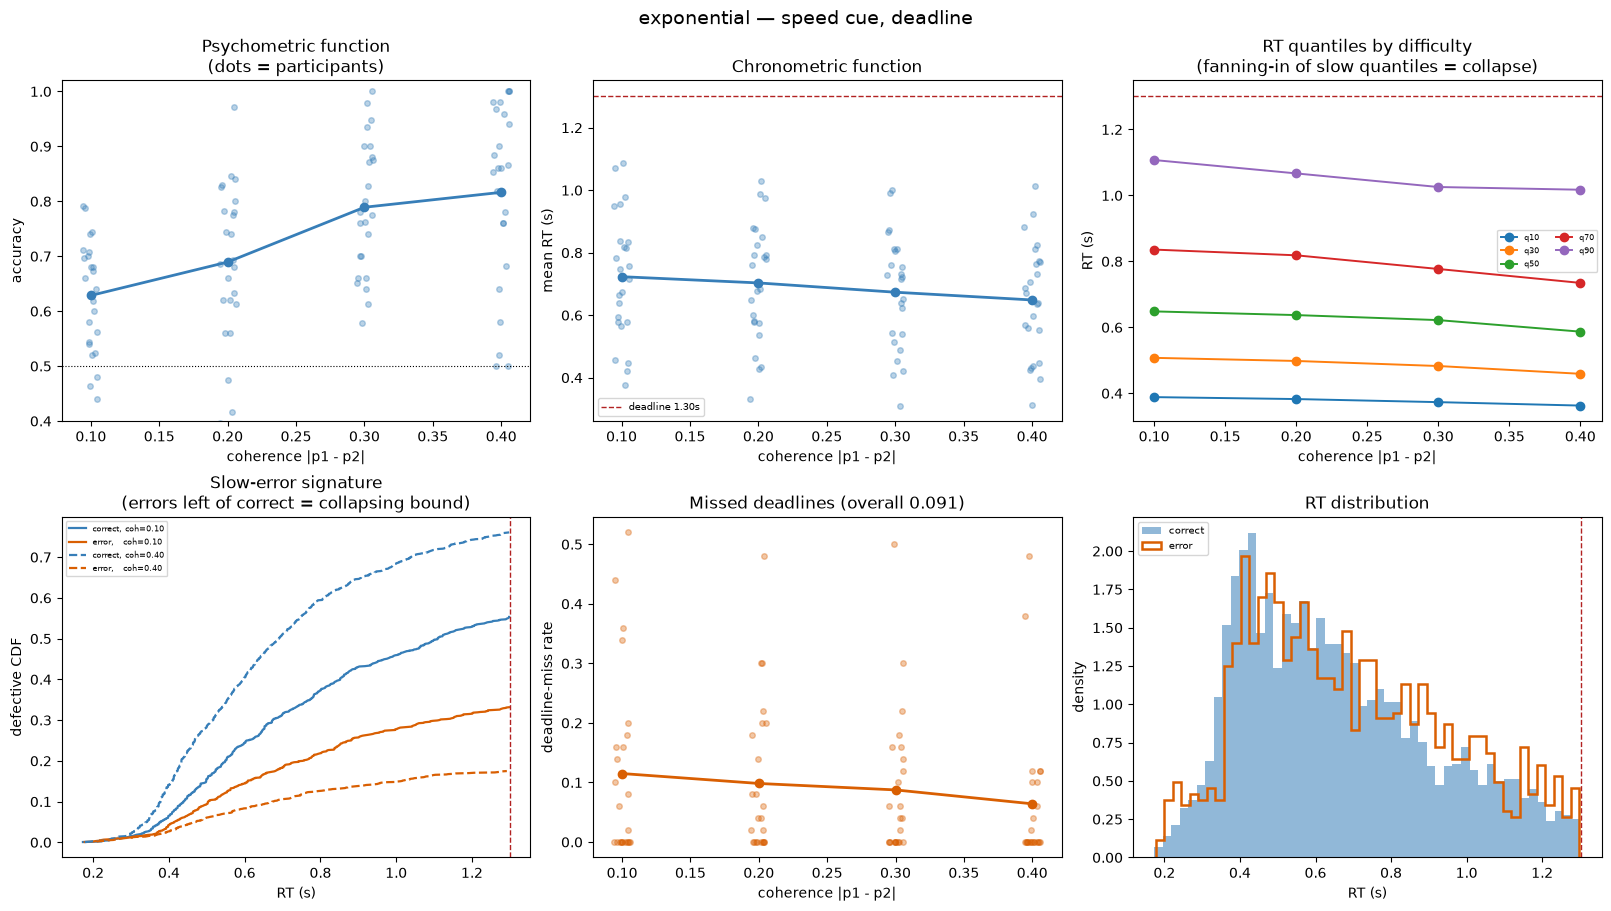

In [49]:
cell_df = emp[(emp.cue == CUE) & (emp.has_deadline == HAS_DEADLINE)]

sim_dfs, sim_truth = {}, {}
for mdl in PROJECT_MODEL_NAMES:
    sim_dfs[mdl], sim_truth[mdl] = simulate_full_dataset(
        mdl,
        n_participants=cell_df.pp.nunique(),   # match the empirical design
        seed=1,
    )
    sim_dfs[mdl].to_csv(f"../data/simulated_data_{mdl}.csv", index=False)
    sim_truth[mdl].to_csv(f"../data/data_true_params_{mdl}.csv", index=False)

for name, d in [("empirical", cell_df)] + list(sim_dfs.items()):
    # plot_design_check(d)
    plot_insight_summary(d, title=f"{name} — speed cue, deadline")

In [50]:
def prepare_empirical(df, cue=CUE, has_deadline=HAS_DEADLINE):
    sub = df[(df["cue"] == cue) & (df["has_deadline"] == has_deadline)]
    per_pp, ids = [], []
    for pp, g in sub.groupby("pp"):
        acc = g["acc"].to_numpy(float)
        choice = np.where(np.isnan(acc), -1, acc).astype(int)   # NaN = missed deadline
        per_pp.append(pack_observations(g["rt"].to_numpy(float), choice,
                                        g["difficulty"].to_numpy(float)))
        ids.append(pp)
    n_min = min(a.shape[0] for a in per_pp)
    return {"obs": np.stack([a[:n_min] for a in per_pp]).astype(np.float32)}, ids, n_min


emp_batch, pp_ids, n_trials = prepare_empirical(emp)
print(emp_batch["obs"].shape, "->", len(pp_ids), "participants x", n_trials, "trials")

emp_post = {mdl: workflows[mdl].approximator.sample(num_samples=1000, conditions=emp_batch)
            for mdl in PROJECT_MODEL_NAMES}

for mdl in PROJECT_MODEL_NAMES:
    print(f"{mdl:12s}", {k: round(float(np.mean(emp_post[mdl][k])), 3)
                         for k in param_names(mdl)})

(24, 194, 4) -> 24 participants x 194 trials


Sampling: 100%|██████████| 1/1 [00:00<00:00, 15.07batch/s]

exponential  {'v_scale': 1.603, 'a': 0.715, 't0': 0.207, 'sv': 0.491, 'lam': 1.261}


In [51]:
QUANTILES = [.1, .3, .5, .7, .9]

def summary_stats(rt, correct, coh, difficulty_levels):
    out = []
    for c_ in difficulty_levels:
        sel = coh == c_
        r = rt[sel & ~np.isnan(rt)]
        out += list(np.quantile(r, QUANTILES)) if r.size > 5 else [np.nan] * len(QUANTILES)
        out.append(np.nanmean(correct[sel]))
    out.append(float(np.mean(np.isnan(rt))))
    return np.array(out)


obs_stats = np.nanmean(np.array([
    summary_stats(np.where(g.acc.notna(), g.rt, np.nan), g.acc.to_numpy(float),
                  g.difficulty.to_numpy(), DIFFICULTY_LEVELS)
    for _, g in cell.groupby("pp")
]), axis=0)

ppc = {}
for mdl in PROJECT_MODEL_NAMES:
    draws = []
    for i in range(len(pp_ids)):
        for j in rng.choice(1000, 20, replace=False):
            p = {k: float(np.asarray(emp_post[mdl][k])[i, j].ravel()[0])
                 for k in param_names(mdl)}          
            rt, ch, coh = ddm_data_simulator(mdl, p, rng=rng)
            draws.append(summary_stats(np.where(ch >= 0, rt, np.nan),
                                       np.where(ch == 1, 1.0, 0.0), coh, DIFFICULTY_LEVELS))
    ppc[mdl] = np.array(draws)
    err = np.nanmean(np.abs(np.nanmean(ppc[mdl], axis=0) - obs_stats))
    print(f"{mdl:12s} mean absolute discrepancy = {err:.4f}")

/var/folders/jr/3bpszr9x45b49g16pt8vxg700000gn/T/ipykernel_95824/1292011223.py:9: RuntimeWarning: Mean of empty slice
  out.append(np.nanmean(correct[sel]))


exponential  mean absolute discrepancy = 0.0280


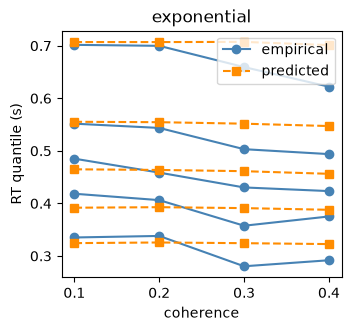

model        predicted miss   (empirical = 0.000)
exponential  0.001


In [52]:
nq = len(QUANTILES)
n_mdl = len(PROJECT_MODEL_NAMES)

fig, axes = plt.subplots(1, n_mdl, figsize=(3.4 * n_mdl, 3.2),
                         sharey=True, squeeze=False, layout="constrained")
axes = axes[0]                     

for ax, mdl in zip(axes, PROJECT_MODEL_NAMES):
    pred = np.nanmean(ppc[mdl], axis=0)
    for qi in range(nq):
        idx = [ci * (nq + 1) + qi for ci in range(len(DIFFICULTY_LEVELS))]
        ax.plot(DIFFICULTY_LEVELS, obs_stats[idx], "o-", color="steelblue",
                label="empirical" if qi == 0 else None)
        ax.plot(DIFFICULTY_LEVELS, pred[idx], "s--", color="darkorange",
                label="predicted" if qi == 0 else None)
    ax.set_title(mdl); ax.set_xlabel("coherence")

axes[0].set_ylabel("RT quantile (s)"); axes[0].legend()
plt.show()

print(f"{'model':12s} predicted miss   (empirical = {obs_stats[-1]:.3f})")
for mdl in PROJECT_MODEL_NAMES:
    print(f"{mdl:12s} {np.nanmean(ppc[mdl][:, -1]):.3f}")

In [ ]:
# yet to test this, confim with paula and try

for n_levels in [1, 2, 6]:
    COHERENCES = {1: np.array([0.35]),
                  2: np.array([0.10, 0.60]),
                  6: np.array([0.10, 0.20, 0.30, 0.40, 0.50, 0.60])}[n_levels]
    N_TRIALS_PER_COH = 360 // n_levels        # hold TOTAL trials constant

    wf = make_workflow("exponential")
    wf.fit_online(epochs=20, batch_size=64, num_batches_per_epoch=200)
    val = wf.simulate(300)
    post = wf.approximator.sample(num_samples=500, conditions=val)
    bf.diagnostics.plots.recovery(post, val)
    plt.suptitle(f"{n_levels} difficulty level(s)"); plt.show()

